# 05 — Clustering y PCA (Unidad IV)

**Proyecto:** Análisis de riesgo crediticio · South German Credit (UCI, id 573)  
**Alumno:** Alexander Domínguez Zárate · UTTT · Unidad IV

**Objetivo:** segmentar los clientes **sin usar la respuesta** (`kredit`) con K-means,
reducir dimensionalidad con PCA y validar post-hoc si los segmentos discriminan riesgo.
Pregunta de negocio: *¿existen grupos naturales de solicitantes con distinta exposición y riesgo?*

**Fuente de verdad:** `src/models/clustering_pca.py`; este notebook reutiliza sus funciones
e interpreta cada paso.


In [1]:
import os
import sys

import pandas as pd
from IPython.display import Image, display

os.chdir('..')
sys.path.insert(0, os.path.abspath('src/models'))

import clustering_pca as clu

print('excluidas por diseño:', clu.EXCLUIDAS)


excluidas por diseño: ['kredit', 'kredit_cat', 'cuota_aprox_mensual']


## 1) Matriz de clustering

**Decisiones de diseño:**

- Se excluyen `kredit`/`kredit_cat`: el clustering es no supervisado y **no debe ver la respuesta**.
- Se excluye `cuota_aprox_mensual`: duplica la información de `hoehe`/`laufzeit`.
- 3 numéricas estandarizadas (`laufzeit`, `hoehe`, `alter`) + 17 categóricas one-hot
  → matriz de 1000 × 71 (las dummies dominan por diseño; es lo que permite a K-means
  tratar el espacio nominal).


In [2]:
df = pd.read_csv(clu.CSV_PATH)
X, nombres, prep = clu.construir_matriz(df)
print('shape del dataset:', df.shape)
print('shape de la matriz de clustering:', X.shape)


shape del dataset: (1000, 40)
shape de la matriz de clustering: (1000, 71)


## 2) PCA — cuánta dimensionalidad se puede comprimir


In [3]:
pca, var, acum, n80, n90, top_load, ruta_scree = clu.pca_completo(X, nombres)
print('componentes:', len(var))
print('varianza de las 5 primeras:', [round(v*100, 1) for v in var[:5]], '%')
print(f'80 % de varianza = {n80} componentes | 90 % = {n90} componentes')
top_load.head(6).round(3)


componentes: 70
varianza de las 5 primeras: [np.float64(15.0), np.float64(10.3), np.float64(5.7), np.float64(4.5), np.float64(4.2)] %
80 % de varianza = 23 componentes | 90 % = 31 componentes


,PC1,PC2
num__hoehe,0.674,-0.074
num__laufzeit,0.643,-0.165
cat__telef_cat_no,-0.138,-0.086
cat__telef_cat_yes,0.138,0.086
cat__verm_cat_unknown,-0.114,0.012
cat__verm_cat_real_estate,0.091,0.079


**Interpretación del PCA.** La varianza está **muy repartida**: la PC1 solo explica 15 % y se
necesitan **23 componentes para el 80 %** (31 para el 90 %). Es el comportamiento esperado con
muchas dummies casi independientes — no existe un "eje del riesgo" único. Lo que sí revela PC1
es la **dimensión de exposición**: sus loadings dominantes son `hoehe` (0.674) y `laufzeit` (0.643),
con signos positivos ambos. Es decir, el primer eje separa *créditos grandes y largos* de *chicos
y cortos*; el resto del espacio son matices categóricos (teléfono, propiedades, empleo).


## 3) Selección de k para K-means (codo + silhouette)


In [4]:
tabla_k = clu.seleccionar_k(X, k_min=2, k_max=8)
tabla_k.round(3)


,k,inercia,silhouette
0,2,10728.269,0.131
1,3,10013.490,0.086
2,4,9643.591,0.070
3,5,9407.208,0.062
4,6,9205.872,0.053
5,7,9028.095,0.055
6,8,8876.033,0.054


**Interpretación de la selección.** El silhouette máximo es **0.131 con k=2** y cae monótonamente
después; el codo de la inercia también se dobla en k≈2–3. Un silhouette de 0.13 es **bajo en
absoluto** (0.25+ sería estructura nítida): en un espacio de 71 dimensiones con dummies, los
clústeres reales se solapan. La lectura correcta no es "hay 2 islas perfectas" sino "la partición
más defendible es binaria y describe el gradiente principal de exposición".


## 4) K-means final (k=2) y perfil de segmentos


In [5]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

km = KMeans(n_clusters=2, n_init=10, random_state=42)
labels = km.fit_predict(X)
print('silhouette final:', round(silhouette_score(X, labels), 3))

base, desvios = clu.perfil_clusters(df, X, nombres, labels)
base


silhouette final: 0.131


,tamaño,pct_bad,plazo_medio,monto_medio,edad_media
cluster,,,,,
0,254,43.7,36.0,6895.2,36.4
1,746,25.3,15.8,2037.4,35.2


**Interpretación de los segmentos.** K-means separa dos economías del crédito:

| | Clúster 0 — "exposición alta" | Clúster 1 — "exposición baja" |
|---|---|---|
| Tamaño | 254 (25 %) | 746 (75 %) |
| Monto medio | **6895 DM** | 2037 DM |
| Plazo medio | 36 meses | 16 meses |
| % bad real | **43.7 %** | 25.3 % |

El clúster de créditos grandes/largos **triplica casi el riesgo** del de créditos pequeños
(43.7 % vs 25.3 %, base 30 %). Validación post-hoc importante: el clustering **nunca vio** `kredit`,
y aun así sus segmentos discriminan riesgo — la exposición es la variable maestra del negocio.
Este hallazgo conecta con Q5 del Data Mart (≥8000 DM → 54.3 % bad) y con la saturación de la
regresión en montos altos.


## 5) Categorías distintivas de cada segmento


In [6]:
for k in sorted(desvios):
    mas = [(v.replace('cat__', ''), round(x, 2)) for v, x in desvios[k].sort_values(ascending=False).head(4).items()]
    menos = [(v.replace('cat__', ''), round(x, 2)) for v, x in desvios[k].sort_values().head(4).items()]
    print(f'--- clúster {k} ---')
    print('  más presentes :', mas)
    print('  más ausentes  :', menos)


--- clúster 0 ---
  más presentes : [('telef_cat_yes', 0.2), ('beruf_cat_high_qual_selfemp', 0.16), ('verm_cat_real_estate', 0.15), ('famges_cat_male_married_widowed', 0.13)]
  más ausentes  : [('telef_cat_no', -0.2), ('verm_cat_unknown', -0.18), ('beruf_cat_unskilled_resident', -0.12), ('moral_cat_no_credits_or_paid', -0.1)]
--- clúster 1 ---
  más presentes : [('telef_cat_no', 0.07), ('verm_cat_unknown', 0.06), ('beruf_cat_unskilled_resident', 0.04), ('moral_cat_no_credits_or_paid', 0.04)]
  más ausentes  : [('telef_cat_yes', -0.07), ('beruf_cat_high_qual_selfemp', -0.06), ('verm_cat_real_estate', -0.05), ('famges_cat_male_married_widowed', -0.04)]


**Interpretación del perfil cualitativo.** El clúster de exposición alta sobre-representa
`telef_yes` (+0.20), `beruf_high_qual_selfemp` (+0.16), `verm_real_estate` (+0.15) y
`verw_car_new` (+0.13): clientes con **empleo calificado e inmueble** que piden más y a más plazo
(y dejan su teléfono registrado — más contacto bancario). El clúster bajo concentra `telef_no`,
`verm_unknown` (sin propiedades conocidas) y `moral_no_credits_or_paid`. Lectura de negocio:
el segmento riesgoso no es el "marginal" sino el **cliente solvente sobreexpuesto**.


## 6) Diagnóstico gráfico


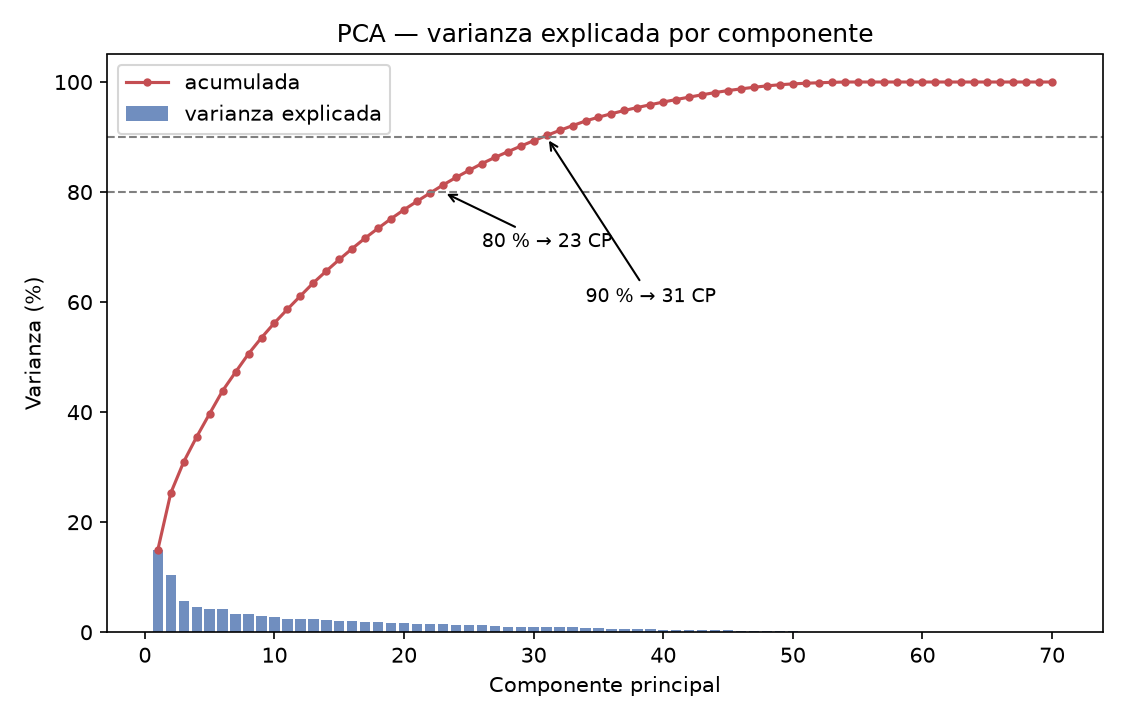

In [7]:
display(Image(filename=ruta_scree))


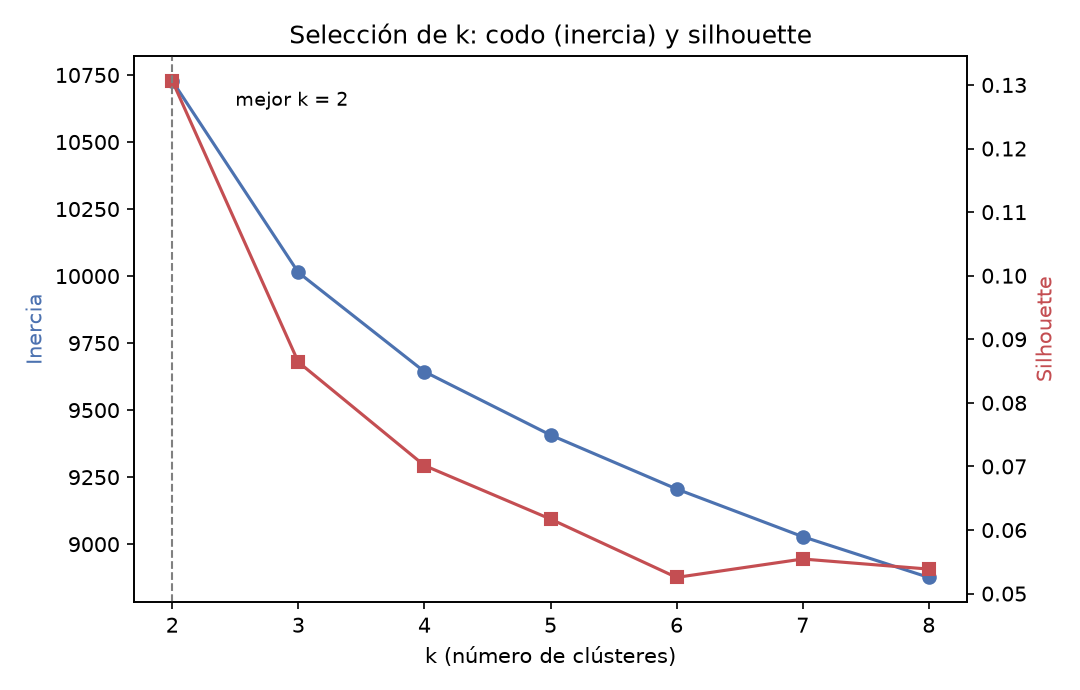

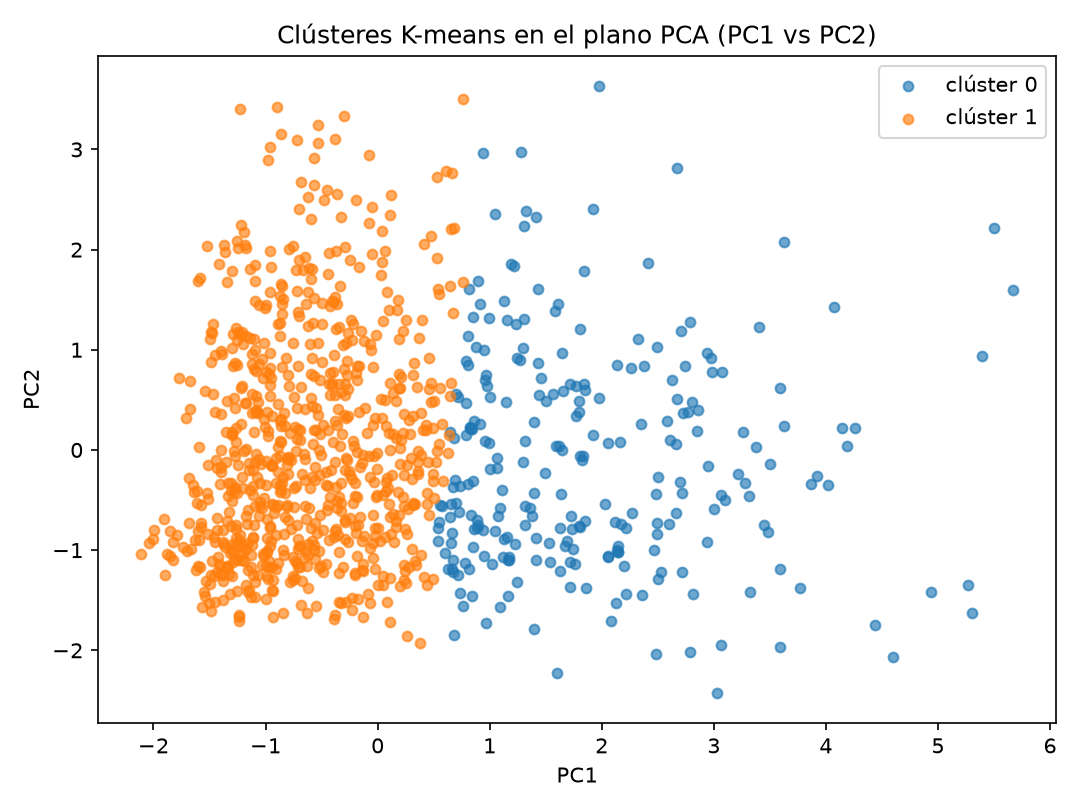

C:\Users\alexa\OneDrive\Escritorio\REC_ECBD_2026_Dominguez_Zarate_Alexander\src\models\clustering_pca.py:185: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


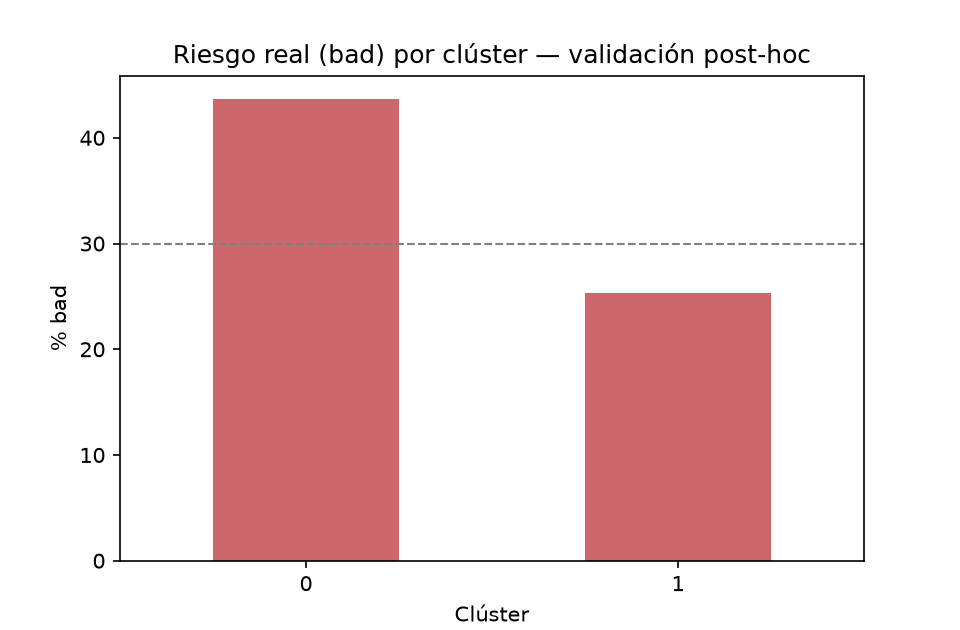

In [8]:
mejor_k, ruta_sel = clu.graficar_seleccion_k(
    tabla_k, 'docs/modelos/figuras/kmeans_seleccion_k.png')
display(Image(filename=ruta_sel))

ruta_scatter = clu.proyectar_2d(pca, X, labels, 'docs/modelos/figuras/pca_clusters.png')
display(Image(filename=ruta_scatter))

ruta_bad = clu.graficar_bad_por_cluster(base, 'docs/modelos/figuras/clu_perfil_bad.png')
display(Image(filename=ruta_bad))


**Interpretación de las figuras.** El scree confirma la repartición de varianza (colas largas).
En el plano PC1–PC2 los dos clústeres se separan principalmente por PC1 — el eje monto×plazo —
con solapamiento en la frontera (coherente con silhouette 0.13): no son islas, son dos colas de
una misma distribución. La barra de % bad muestra el gradiente de riesgo real por segmento frente
a la línea base del 30 %.


## 7) Reproducción completa y artefactos


In [9]:
salida = clu.main()


dataset: (1000, 40)
matriz de clustering: (1000, 71)


PCA: 70 componentes | 80% var = 23 CP | 90% = 31 CP
top loadings PC1:
                             PC1    PC2
num__hoehe                 0.674 -0.074
num__laufzeit              0.643 -0.165
cat__telef_cat_no         -0.138 -0.086
cat__telef_cat_yes         0.138  0.086
cat__verm_cat_unknown     -0.114  0.012
cat__verm_cat_real_estate  0.091  0.079



selección de k:
 k   inercia  silhouette
 2 10728.269       0.131
 3 10013.490       0.086
 4  9643.591       0.070
 5  9407.208       0.062
 6  9205.872       0.053
 7  9028.095       0.055
 8  8876.033       0.054


mejor k por silhouette: 2



perfil de clústeres:
         tamaño  pct_bad  plazo_medio  monto_medio  edad_media
cluster                                                       
0           254     43.7         36.0       6895.2        36.4
1           746     25.3         15.8       2037.4        35.2


C:\Users\alexa\OneDrive\Escritorio\REC_ECBD_2026_Dominguez_Zarate_Alexander\src\models\clustering_pca.py:185: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()



metricas guardadas: modelos\clustering\metricas.json
figuras: ['docs\\modelos\\figuras\\pca_varianza.png', 'docs\\modelos\\figuras\\kmeans_seleccion_k.png', 'docs\\modelos\\figuras\\pca_clusters.png', 'docs\\modelos\\figuras\\clu_perfil_bad.png']


## 8) Conclusión de la Unidad IV

- **PCA:** la varianza está repartida (PC1 = 15 %); el eje dominante es la **exposición**
  (monto × plazo). Comprimir al 80 % requiere 23 componentes — el dataset no tiene una
  estructura latente simple.
- **Clustering:** la partición óptima es **k=2** (silhouette 0.131): *exposición alta*
  (254 clientes, 43.7 % bad) vs. *exposición baja* (746, 25.3 % bad).
- **Valor de negocio:** los segmentos, calculados sin ver la respuesta, discriminan riesgo
  real y sugieren una política diferenciada: límites y revisión reforzada para el segmento
  de alta exposición.
- **Limitación:** silhouette bajo = clústeres con solape; úsese como segmentación
  gerencial (2 reglas: monto/plazo), no como identificador rígido de clientes.

**Siguiente (Fase 5):** dashboard HTML estático + README final.
